In [35]:
import obspy
from obspy import read
from geopy.distance import geodesic
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import datetime
from obspy.signal.filter import lowpass
from obspy.clients.fdsn.client import Client
import json
import scipy
import xarray as xr
from matplotlib.colors import LightSource
import cartopy.crs as ccrs         # to plot maps with different projections
import cartopy.feature as cfeature # to plot coastlines, land, borders, etc.
import json
import matplotlib
from matplotlib import colors
from pyproj import Proj
from geopy.distance import geodesic
import pickle
import matplotlib.animation as animation
matplotlib.rcParams['font.family'] = ['Arial']
plt.rcParams.update({'font.size': 14}) 
from math import radians, cos, sin, atan2, sqrt, degrees
import imageio
from itertools import product
import dask
from dask.diagnostics import ProgressBar
with open('/Users/zoekrauss/offshore_eew_modeling/location/PB2002_boundaries.json', 'r') as f:
    plate_boundaries = json.load(f)

from geopy.distance import geodesic

In [36]:
eq_origin_time = obspy.UTCDateTime(2011,3,11,5,46,24)
eq_lat = 38.297
eq_lon = 142.373

pvel = 6.0 # km/s

In [37]:
# Read in station information
network = []
station = []
location = []
channel = []
lat = []
lon = []
gain = []
with open('20110311_japan_subduction11.dat', mode='r', encoding='utf-8') as file:
    for line in file:
        try:
            objects = [l for l in line.split(' ') if l!='']
            if (len(objects)==15) & (objects[0][0]=='K'):
                network.append(objects[0])
                station.append(objects[1])
                channel.append(objects[3])
                lat.append(float(objects[4]))
                lon.append(float(objects[5]))
                gain.append(float(objects[8]))
        except:
            continue

# For each station location, estimate a P wave arrival time
dist = []
ptime = []
for i in range(len(station)):
    # Get distance between station and earthquake
    sta_dist = geodesic((eq_lat,eq_lon),(lat[i],lon[i])).km
    # Estimate P travel time
    p_tt = sta_dist / pvel
    # Estimate P arrival time
    p_arr = eq_origin_time + p_tt

    dist.append(sta_dist)
    ptime.append(p_arr)

In [38]:
import glob
# VERTICAL CHANNELS ONLY:
all_miniseeds = glob.glob('20110311_japan_subduction11_miniseeds/*Z*')      

In [39]:
dat_ind = [j for j,s in enumerate(station) if s=='J0654'][0]
dist[dat_ind]

86.2535979171615

In [40]:
p_amps = []
all_amps = []
p_ds_amps = []
all_ds_amps = []
all_sta_dists = []
for i in range(len(all_miniseeds)):
    mseed = all_miniseeds[i]
    st = read(mseed)

    dat_ind = [j for j,s in enumerate(station) if s==st[0].stats.station][0]
    sta_lat = lat[dat_ind]
    sta_lon = lon[dat_ind]
    sta_gain = gain[dat_ind]
    sta_ptime = ptime[dat_ind]
    sta_dist = dist[dat_ind]

    p_sec = sta_ptime - st[0].stats.starttime 

    if sta_dist > 200:
        continue
        
    if p_sec < 0:
        continue

    sta_data = st[0].data / sta_gain

    # Get original amplitudes
    p_window_ind = [j for j,t in enumerate(st[0].times()) if (t>p_sec - 10) & (t<p_sec+10)]
    p_data = [sta_data.data[j] for j in p_window_ind]
    p_amp = np.max(np.abs(p_data))
    p_amps.append(p_amp)
    all_amps.append(np.max(np.abs(sta_data)))

    # Now downsample
    st2 = st.copy()
    t1 = st2[0].stats.starttime
    t2 = st2[0].stats.endtime
    st2.trim(t1-5,t2+5,fill_value=np.int32(np.mean(st2[0].data)),pad=True) # pad ends so we can cut off edge effects
    factor = int(st2[0].stats.sampling_rate/8)
    st2.decimate(factor,no_filter=True)
    # st2.resample(8.0,no_filter=False)
    st2.trim(t1,t2) # cut off edge effects

    sta_data = st2[0].data / sta_gain

    # Get downsampled amplitudes
    p_window_ind = [j for j,t in enumerate(st2[0].times()) if (t>p_sec - 3) & (t<p_sec+2)]
    p_data = [sta_data.data[j] for j in p_window_ind]
    p_amp = np.max(np.abs(p_data))
    p_ds_amps.append(p_amp)
    all_ds_amps.append(np.max(np.abs(sta_data)))

    all_sta_dists.append(sta_dist)

In [41]:
p_ratios = np.array(p_ds_amps) / np.array(p_amps)
all_ratios = np.array(all_ds_amps) / np.array(all_amps)

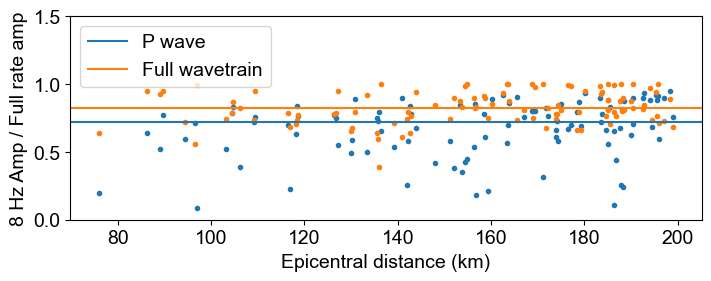

In [42]:
fig,ax = plt.subplots(1,figsize=[7,2.7],constrained_layout = True)
ax.plot(all_sta_dists,p_ratios,'.')
ax.plot(all_sta_dists,all_ratios,'.')

ax.axhline(np.median(p_ratios),color='tab:blue',label='P wave')
ax.axhline(np.median(all_ratios),color='tab:orange',label='Full wavetrain')

ax.legend(loc='upper left')

ax.set_ylim(0,1.5)
ax.set_xlabel('Epicentral distance (km)')
ax.set_ylabel('8 Hz Amp / Full rate amp')

fig.patch.set_facecolor('none')  # Makes the outer figure background transparent
ax.patch.set_facecolor('white')  # Keeps the inner axes background solid white


# plt.savefig('/Users/zoekrauss/shakealert_8hz/kona_figs/japan_amplitude_scatter.png', dpi=300)

In [43]:
np.median(p_ratios)

0.7228303025079721

In [44]:
np.median(all_ratios)

0.8217749118691272